In [11]:
%pip install numpy
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 109.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 433.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [7]:
import numpy as np

images = np.load("../data/brain_train_image_final.npy")
labels = np.load("../data/brain_train_label.npy")

print("Image shape:", images.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", images.min(), images.max())

print("Label shape:", labels.shape)
print("First 10 labels:", labels[:10])

# Handles labels shaped (N,), (N, 1), or one-hot labels (N, 3).
if labels.ndim == 2 and labels.shape[1] == 3:
    class_ids = labels.argmax(axis=1)
else:
    class_ids = labels.reshape(-1)

print("Classes and counts:", np.unique(class_ids, return_counts=True))
assert len(images) == len(labels), "Image and label counts do not match"

Image shape: (1657, 2, 100, 76)
Image dtype: float32
Pixel range: 0.0 1.0
Label shape: (1657,)
First 10 labels: [1 1 1 2 1 1 2 0 1 1]
Classes and counts: (array([0, 1, 2]), array([612, 477, 568]))


In [8]:
!pip3 install matplotlib

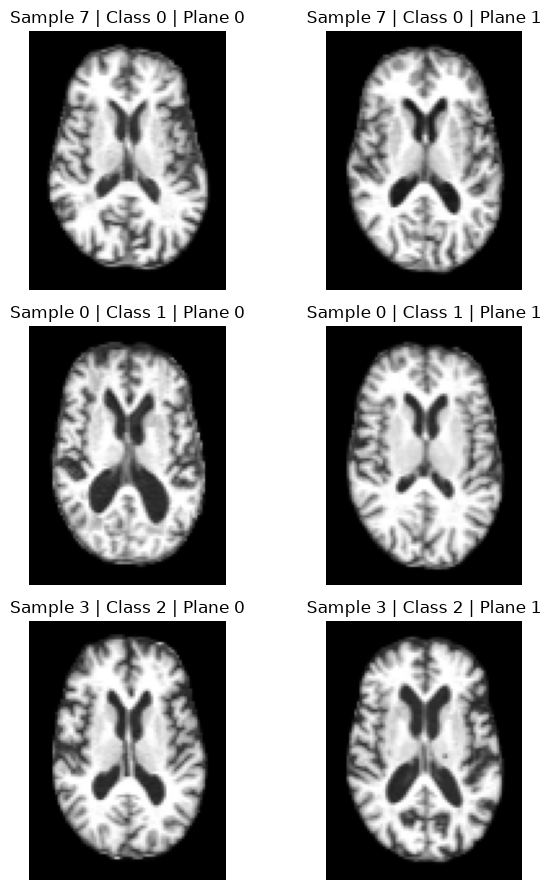

In [9]:
import matplotlib.pyplot as plt
import numpy as np

# Show one training example from each numeric class.
indices = [np.flatnonzero(labels == c)[0] for c in np.unique(labels)]

fig, axes = plt.subplots(3, 2, figsize=(7, 9))

for row, idx in enumerate(indices):
    for plane in range(2):
        axes[row, plane].imshow(
            images[idx, plane],
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        axes[row, plane].set_title(
            f"Sample {idx} | Class {labels[idx]} | Plane {plane}"
        )
        axes[row, plane].axis("off")

plt.tight_layout()
plt.savefig("training_planes.png", dpi=150)
plt.show()

In [12]:
# Generate training/testing split
from pathlib import Path

import numpy as np
from sklearn.model_selection import train_test_split

# Assumes the notebook's working directory is notebooks/.
project_root = Path("..").resolve()
data_dir = project_root / "data"

images = np.load(data_dir / "brain_train_image_final.npy")
labels = np.load(data_dir / "brain_train_label.npy")

# Support integer labels or one-hot labels.
if labels.ndim == 2 and labels.shape[1] == 3:
    y = labels.argmax(axis=1)
else:
    y = labels.reshape(-1)

assert len(images) == len(y)
assert set(np.unique(y)) == {0, 1, 2}

# Split original example indices, keeping each example's planes together.
indices = np.arange(len(y))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y,
)

# Check that the subsets are disjoint and cover all examples.
assert np.intersect1d(train_idx, val_idx).size == 0
assert np.array_equal(
    np.sort(np.concatenate([train_idx, val_idx])),
    indices,
)

# Store outside data/ so the team can share the split through Git.
split_dir = project_root / "splits"
split_dir.mkdir(parents=True, exist_ok=True)
split_path = split_dir / "train_val_seed42.npz"

np.savez(
    split_path,
    train_idx=train_idx,
    val_idx=val_idx,
    labels=y,
    seed=np.array(42),
    validation_fraction=np.array(0.20),
)

print("Training examples:", len(train_idx))
print("Validation examples:", len(val_idx))

for name, subset in [("Training", train_idx), ("Validation", val_idx)]:
    classes, counts = np.unique(y[subset], return_counts=True)
    print(f"{name} class counts:", dict(zip(classes.tolist(), counts.tolist())))

print("Saved:", split_path)

Training examples: 1325
Validation examples: 332
Training class counts: {0: 489, 1: 382, 2: 454}
Validation class counts: {0: 123, 1: 95, 2: 114}
Saved: /sfs/gpfs/tardis/home/xdz3ke/mlia-simclr-brain/splits/train_val_seed42.npz
